# Task 4 - BERT Text Classification

This notebook compares a simple TF-IDF + Logistic Regression baseline against a fine-tuned DistilBERT sentiment classifier on IMDB reviews.

## Notebook Settings

Environment and task variables used in this run:

- `DATASET_NAME = "Preprocessed IMDB"`
- `TRAIN_SUBSET_SIZE = 5000`
- `VALIDATION_SUBSET_SIZE = 1000`
- `TEST_SUBSET_SIZE = 1000`
- `TFIDF_MAX_FEATURES = 10000`
- `MODEL_NAME = "distilbert-base-uncased"`
- `MAX_LENGTH = 256`
- `BATCH_SIZE = 16`
- `LEARNING_RATE = 2e-5`
- `EPOCHS = 3`
- `DEVICE = "cuda:0" if CUDA is available, otherwise "cpu"`
- `SEED = 42`

The notebook was trained on Google Colab with GPU when CUDA was available, but it keeps CPU-friendly subset sizes and hyperparameters. Validation rows are sampled from the IMDB training split, while the IMDB test split is held out for final evaluation only.

## Setup

In [10]:
from pathlib import Path
import random
import sys
from IPython.display import Image, display

from datasets import load_from_disk
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

In [11]:
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", None)
pd.set_option("display.max_columns", None)

In [12]:
PROJECT_ROOT = Path.cwd().resolve()
for candidate in (PROJECT_ROOT, *PROJECT_ROOT.parents):
    if (candidate / "src" / "classification_utils.py").is_file():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError(
        "Could not locate the project root containing src/classification_utils.py"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

## Imports

The project root is added to `sys.path`, so the source package is importable from both the repository root and the `notebooks/` directory.

In [13]:
# Imports are intentionally package-qualified so they match the repository layout.

In [14]:
from src.classification_utils import (
    build_confusion_matrix_frame,
    create_review_loader,
    dataset_split_to_frame,
    evaluate_distilbert,
    get_misclassified_examples,
    split_train_validation_frame,
    train_distilbert,
    train_tfidf_baseline,
)
from src.config import METADATA_DIR, PLOTS_DIR, PREPROCESSED_DATA_DIR, SEED, TABLES_DIR
from src.plotting import save_confusion_matrix_plot, save_dual_axis_line_plot
from src.result_saver import save_dataframe, save_json

In [15]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [16]:
for output_dir in [METADATA_DIR, PLOTS_DIR, TABLES_DIR]:
    output_dir.mkdir(parents=True, exist_ok=True)

## Load IMDB Data

The notebook uses the preprocessed IMDB dataset from Task 0. In the Colab run, the project files and saved results were accessed through Google Drive.

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
IMDB_PATH = '/content/drive/MyDrive/Colab Notebooks/Loka/preprocessed/'+ "imdb"
imdb_dataset = load_from_disk(str(IMDB_PATH))

In [19]:
imdb_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 24902
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 24676
    })
})

## Prepare Train, Validation, And Test Subsets

Task 4 uses documented stratified subsets. The validation subset is taken from the IMDB training split and is kept separate from the final IMDB test subset, so model tuning does not leak into final evaluation.

In [20]:
DATASET_NAME = "Preprocessed IMDB"
TRAIN_SUBSET_SIZE = 5000
VALIDATION_SUBSET_SIZE = 1000
TEST_SUBSET_SIZE = 1000

In [21]:
DATASET_NAME, TRAIN_SUBSET_SIZE, VALIDATION_SUBSET_SIZE, TEST_SUBSET_SIZE

('Preprocessed IMDB', 5000, 1000, 1000)

In [22]:
train_validation_frame = dataset_split_to_frame(
    dataset_split=imdb_dataset["train"],
    sample_size=TRAIN_SUBSET_SIZE + VALIDATION_SUBSET_SIZE,
    seed=SEED,
)

train_frame, validation_frame = split_train_validation_frame(
    frame=train_validation_frame,
    validation_size=VALIDATION_SUBSET_SIZE,
    seed=SEED,
)

In [23]:
test_frame = dataset_split_to_frame(
    dataset_split=imdb_dataset["test"],
    sample_size=TEST_SUBSET_SIZE,
    seed=SEED,
)

In [24]:
train_frame.shape, validation_frame.shape, test_frame.shape

((5000, 2), (1000, 2), (1000, 2))

In [25]:
train_frame.head()

,text,label
0,"Everyone, my name may sound weird, but there was nothing else! Any way, I haven't seen anything like this before so it was crazy! Of course that's a good th...",1
1,"Poor Basil Rathbone, an egotistical composer who's lost his muse. He's been faking it for some time, buying his lyrics and his music from various sources. T...",1
2,This Movie has great fight scenes. Now its true that the acting is a little rough. But If I wanted to see a movie based on acting skills I would watch a Che...,1
3,"The characters were alive and interesting, the plot was excellently paced, the pyro effects were masterfully accomplished, and it takes a basic love triangl...",1
4,"Ever since seeing this film as a child, over 30 years ago, I never tire of watching it. From the opening scenes in the horn factory, to the car motor runnin...",1


In [26]:
validation_frame["label"].value_counts().sort_index()

,count
label,
0,499
1,501


In [27]:
pd.DataFrame(
    {
        "split": ["train", "validation", "test"],
        "rows": [len(train_frame), len(validation_frame), len(test_frame)],
        "negative": [
            int(train_frame["label"].eq(0).sum()),
            int(validation_frame["label"].eq(0).sum()),
            int(test_frame["label"].eq(0).sum()),
        ],
        "positive": [
            int(train_frame["label"].eq(1).sum()),
            int(validation_frame["label"].eq(1).sum()),
            int(test_frame["label"].eq(1).sum()),
        ],
    }
)

,split,rows,negative,positive
0,train,5000,2496,2504
1,validation,1000,499,501
2,test,1000,497,503


**Observation:** The split table shows 5,000 training rows, 1,000 validation rows, and 1,000 test rows. The label counts are close to balanced in every split: train has 2,496 negative and 2,504 positive reviews, validation has 499 negative and 501 positive reviews, and test has 497 negative and 503 positive reviews. The validation rows come from the IMDB training split, while the test rows come from the IMDB test split and are used only for final evaluation.

## Save Training Config

In [28]:
TFIDF_MAX_FEATURES = 10000
MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 256
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
EPOCHS = 3
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [29]:
training_config = {
    "task": "Task 4 - BERT Text Classification",
    "dataset": DATASET_NAME,
    "train_subset_size": TRAIN_SUBSET_SIZE,
    "validation_subset_size": VALIDATION_SUBSET_SIZE,
    "test_subset_size": TEST_SUBSET_SIZE,
    "tfidf_max_features": TFIDF_MAX_FEATURES,
    "model_name": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "device": str(DEVICE),
    "seed": SEED,
    "sampling_method": "stratified by label distribution",
    "train_validation_source_split": "IMDB train",
    "test_source_split": "IMDB test",
    "subsampling_reason": "CPU-friendly DistilBERT fine-tuning.",
}

In [30]:
training_config

{'task': 'Task 4 - BERT Text Classification',
 'dataset': 'Preprocessed IMDB',
 'train_subset_size': 5000,
 'validation_subset_size': 1000,
 'test_subset_size': 1000,
 'tfidf_max_features': 10000,
 'model_name': 'distilbert-base-uncased',
 'max_length': 256,
 'batch_size': 16,
 'learning_rate': 2e-05,
 'epochs': 3,
 'device': 'cuda:0',
 'seed': 42,
 'sampling_method': 'stratified by label distribution',
 'train_validation_source_split': 'IMDB train',
 'test_source_split': 'IMDB test',
 'subsampling_reason': 'CPU-friendly DistilBERT fine-tuning.'}

In [31]:
save_json(
    data=training_config,
    output_path=METADATA_DIR / "task4_training_config.json",
)

## TF-IDF + Logistic Regression Baseline

This baseline is simple and fast. It gives DistilBERT a number to beat before paying the cost of transformer fine-tuning.

In [32]:
baseline_model, tfidf_vectorizer, baseline_metrics = train_tfidf_baseline(
    train_frame=train_frame,
    test_frame=test_frame,
    max_features=TFIDF_MAX_FEATURES,
)

In [33]:
baseline_metrics

{'accuracy': 0.863,
 'macro_f1': 0.8629834209939402,
 'training_time_seconds': 1.4270589351654053}

**Observation:** The TF-IDF baseline reached **0.863 accuracy** and **0.863 macro F1** on the held-out test subset, with training and evaluation taking about **1.43 seconds** in this notebook run. This is a strong and very fast baseline, so DistilBERT needs a meaningful test-set improvement to justify its extra compute cost.

## Load DistilBERT

The pretrained DistilBERT body is loaded from `distilbert-base-uncased`, and a new two-label classification head is initialized for IMDB sentiment.

In [34]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [35]:
distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [36]:
print(type(tokenizer).__name__)
print(type(distilbert_model).__name__)
print("number of labels:", distilbert_model.config.num_labels)

BertTokenizer
DistilBertForSequenceClassification
number of labels: 2


## Create Dataloaders

The tokenizer pads and truncates every review to `MAX_LENGTH = 256`, as requested in the task. With `BATCH_SIZE = 16`, the training, validation, and test subsets each become separate dataloaders.

In [37]:
train_loader = create_review_loader(
    frame=train_frame,
    tokenizer=tokenizer,
    max_length=MAX_LENGTH,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

In [38]:
validation_loader = create_review_loader(
    frame=validation_frame,
    tokenizer=tokenizer,
    max_length=MAX_LENGTH,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [39]:
test_loader = create_review_loader(
    frame=test_frame,
    tokenizer=tokenizer,
    max_length=MAX_LENGTH,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [40]:
len(train_loader), len(validation_loader), len(test_loader)

(313, 63, 63)

In [41]:
first_batch = next(iter(train_loader))

In [42]:
{
    key: value.shape
    for key, value in first_batch.items()
}

{'input_ids': torch.Size([16, 256]),
 'attention_mask': torch.Size([16, 256]),
 'labels': torch.Size([16])}

**Observation:** Each batch has `input_ids`, `attention_mask`, and `labels`. The token tensors should have shape `(batch_size, 256)`, and the labels should have shape `(batch_size)`, so each row is represented with 256 token positions after padding or truncation.

## Fine-Tune DistilBERT

This uses a plain PyTorch training loop, not the HuggingFace Trainer API. The loop handles batches, loss, backpropagation, optimizer steps, and validation accuracy. Validation accuracy is measured on the held-out validation subset from the IMDB training split, not on the final test subset.

In [43]:
distilbert_model, training_history_df, distilbert_training_time = train_distilbert(
    model=distilbert_model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    learning_rate=LEARNING_RATE,
    epochs=EPOCHS,
    device=DEVICE,
)

In [44]:
training_history_df

,epoch,training_loss,validation_accuracy
0,1,0.374243,0.878
1,2,0.179073,0.879
2,3,0.086683,0.883


In [45]:
distilbert_training_time

371.85036969184875

**Observation:** The training history shows that DistilBERT fit the training data strongly: loss dropped from **0.374** in epoch 1 to **0.087** in epoch 3. Validation accuracy improved only slightly from **0.878** to **0.883**, so the later epochs reduced training loss much more than they improved validation performance. Because this validation subset is separate from the final test subset, it can guide model choices without leaking into final evaluation.

## Save Training And Validation Curves

Training loss and validation accuracy use different scales, so the plot uses two y-axes on one figure.

In [46]:
curve_plot_path = PLOTS_DIR / "task4_training_validation_curves.png"

for output_path in [
    curve_plot_path,
    PLOTS_DIR / "task4_training_loss.png",
    PLOTS_DIR / "task4_validation_accuracy.png",
]:
    save_dual_axis_line_plot(
        x_values=training_history_df["epoch"].tolist(),
        left_y_values=training_history_df["training_loss"].tolist(),
        right_y_values=training_history_df["validation_accuracy"].tolist(),
        title="Task 4 DistilBERT Training Loss And Validation Accuracy",
        x_label="Epoch",
        left_y_label="Training loss",
        right_y_label="Validation accuracy",
        left_series_label="Training loss",
        right_series_label="Validation accuracy",
        output_path=output_path,
    )

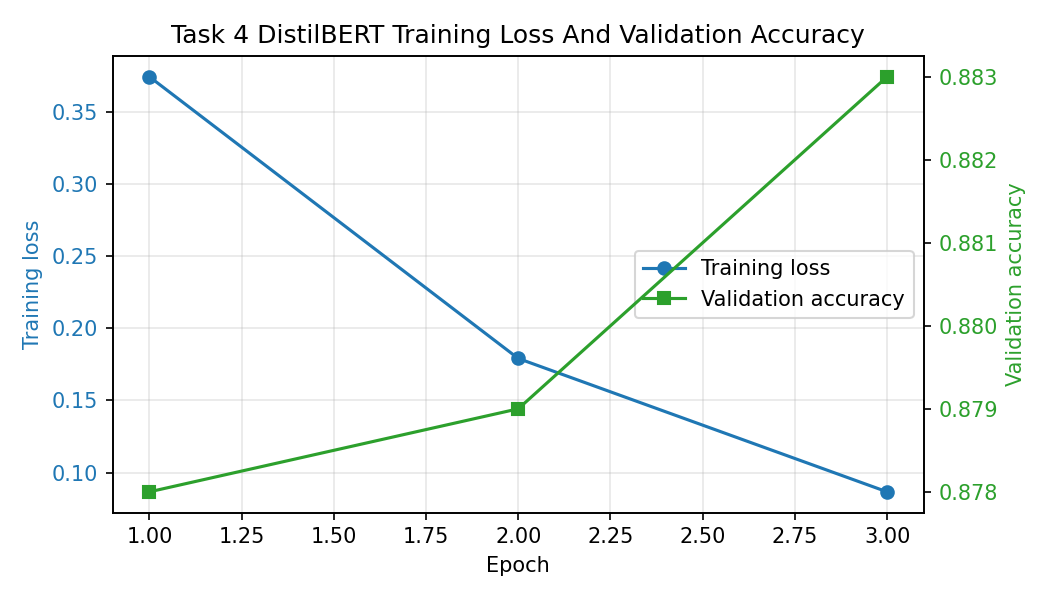

saved: /results/plots/task4_training_validation_curves.png
also saved deliverable copies: /results/plots/task4_training_loss.png
also saved deliverable copies: /results/plots/task4_validation_accuracy.png


In [47]:
display(Image(filename=curve_plot_path))
print("saved:", curve_plot_path)
print("also saved deliverable copies:", PLOTS_DIR / "task4_training_loss.png")
print("also saved deliverable copies:", PLOTS_DIR / "task4_validation_accuracy.png")

## Evaluate DistilBERT

This evaluates the fine-tuned model on the final 1,000-review stratified test subset. This test subset was not used during DistilBERT training or validation.

In [48]:
distilbert_result = evaluate_distilbert(
    model=distilbert_model,
    data_loader=test_loader,
    device=DEVICE,
)

In [49]:
{
    "accuracy": distilbert_result["accuracy"],
    "macro_f1": distilbert_result["macro_f1"],
}

{'accuracy': 0.87, 'macro_f1': 0.8699479791916767}

**Observation:** DistilBERT reached **0.870 accuracy** and **0.870 macro F1** on the final held-out test subset. This is below the final validation accuracy of **0.883**, which suggests the validation subset was slightly easier than the test subset or that the model did not generalize quite as well to the test rows.

## Confusion Matrix

The confusion matrix is normalized by the true class, so each row shows the share of that class predicted as negative or positive.

In [50]:
confusion_matrix_df = build_confusion_matrix_frame(
    labels=distilbert_result["labels"],
    predictions=distilbert_result["predictions"],
)
save_confusion_matrix_plot(
    matrix=confusion_matrix_df,
    title="Task 4 DistilBERT Normalized Confusion Matrix",
    output_path=PLOTS_DIR / "task4_confusion_matrix.png",
)

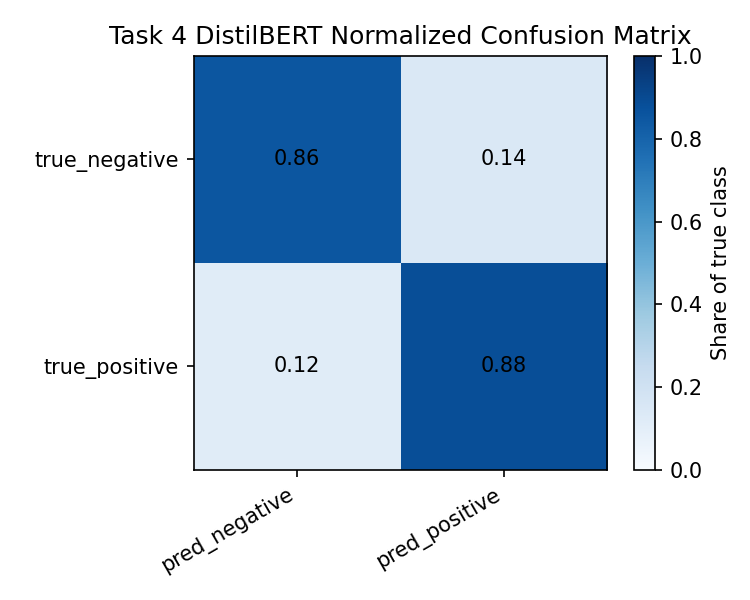

In [51]:
Image(filename=PLOTS_DIR / "task4_confusion_matrix.png")

In [52]:
print("saved:", PLOTS_DIR / "task4_confusion_matrix.png")

saved: /results/plots/task4_confusion_matrix.png


**Observation:** The diagonal cells are the correct predictions. This plot helps check whether the model is mostly balanced or whether it is better at one sentiment class than the other.

## Misclassified Examples

These examples show reviews where DistilBERT predicted the wrong sentiment label, along with its confidence.

In [53]:
misclassified_examples_df = get_misclassified_examples(
    test_frame=test_frame,
    labels=distilbert_result["labels"],
    predictions=distilbert_result["predictions"],
    confidences=distilbert_result["confidences"],
    sample_count=5,
)

In [54]:
misclassified_examples_df

,text,true_label,predicted_label,confidence
0,"I felt cheated out of knowing the whole story. While there could be a twist, this twist was so significant, that I felt betrayed. I believe it could have us...",positive,negative,0.533700
1,"Let's get the flaw out of the way right off the top - the movie should have been much longer. Ray Charles was a brilliant, fascinating man who lead a comple...",positive,negative,0.574217
2,What exactly do people expect when they watch an Al Adamson film? Are they expecting classic cinema that is wonderful beyond belief and will leave them with...,positive,negative,0.826016
3,If you're OK with the outlandish work of Italy's premier horror directorable to accept his outrageous story lines and flamboyant stylethen you should have...,positive,negative,0.864915
4,"Though some would prefer to comment on the value of Bond movies in the connection of learning frequency, and while most of the jargon that tends to limit Bo...",negative,positive,0.971353


In [55]:
save_dataframe(
    dataframe=misclassified_examples_df,
    output_path=TABLES_DIR / "task4_misclassified_examples.csv",
)

**Observation:** The displayed mistakes show several positive reviews predicted as negative and one negative review predicted as positive with high confidence. The positive reviews often contain criticism, caveats, or genre-specific language before arriving at an overall positive judgment, which can make them look negative to the classifier. The negative example contains positive-sounding wording such as interest and plausibility, which helps explain why it was predicted as positive.

## Model Comparison

This table compares the baseline and DistilBERT using the same held-out stratified test set.

In [56]:
model_comparison_df = pd.DataFrame([
    {
        "model": "TF-IDF + Logistic Regression",
        "test_accuracy": baseline_metrics["accuracy"],
        "macro_f1": baseline_metrics["macro_f1"],
        "training_time_seconds": baseline_metrics["training_time_seconds"],
    },
    {
        "model": "DistilBERT fine-tuned",
        "test_accuracy": distilbert_result["accuracy"],
        "macro_f1": distilbert_result["macro_f1"],
        "training_time_seconds": distilbert_training_time,
    },
])

In [57]:
model_comparison_df

,model,test_accuracy,macro_f1,training_time_seconds
0,TF-IDF + Logistic Regression,0.863,0.862983,1.427059
1,DistilBERT fine-tuned,0.870,0.869948,371.850370


<!-- task4_comparison_observation -->
**Observation:** The comparison table shows that DistilBERT scored slightly higher than TF-IDF on the test set: **0.870 accuracy** versus **0.863**, an improvement of about **0.7 percentage points**. The tradeoff is compute cost: DistilBERT took about **372 seconds** in this notebook run, while TF-IDF took about **1.43 seconds**. For this split, the accuracy gain is real but small relative to the extra training time.

In [58]:
save_dataframe(
    dataframe=model_comparison_df,
    output_path=TABLES_DIR / "task4_model_comparison.csv",
)

## Save Metrics

The metrics JSON saves the baseline result, DistilBERT result, training history, and interpretation so the frontend can load the results without rerunning training.

In [ ]:
task4_metrics = {
    "task": "Task 4 - BERT Text Classification",
    "baseline": baseline_metrics,
    "distilbert": {
        "test_accuracy": distilbert_result["accuracy"],
        "test_macro_f1": distilbert_result["macro_f1"],
        "training_time_seconds": distilbert_training_time,
    },
    "training_history": training_history_df.to_dict("records"),
    "main_result": "Compare DistilBERT against the TF-IDF baseline using held-out test accuracy, macro F1, and training time.",
    "interpretation": "DistilBERT improved test accuracy only slightly over TF-IDF while taking much longer to train, so the baseline is the better practical choice for this setup. With 10x less data TF-IDF is even more attractive; with 10x more data both models should be evaluated again because the transformer may benefit more from the larger corpus.",
}

In [60]:
task4_metrics

{'task': 'Task 4 - BERT Text Classification',
 'baseline': {'accuracy': 0.863,
  'macro_f1': 0.8629834209939402,
  'training_time_seconds': 1.4270589351654053},
 'distilbert': {'test_accuracy': 0.87,
  'test_macro_f1': 0.8699479791916767,
  'training_time_seconds': 371.85036969184875},
 'training_history': [{'epoch': 1,
   'training_loss': 0.3742431136318289,
   'validation_accuracy': 0.878},
  {'epoch': 2,
   'training_loss': 0.17907342766991818,
   'validation_accuracy': 0.879},
  {'epoch': 3,
   'training_loss': 0.08668292044980315,
   'validation_accuracy': 0.883}],
 'main_result': 'Compare DistilBERT against the TF-IDF baseline using held-out test accuracy, macro F1, and training time.',
 'interpretation': 'DistilBERT is only worth the extra complexity if it improves enough over the much cheaper TF-IDF baseline on the final test subset.'}

In [61]:
save_json(
    data=task4_metrics,
    output_path=METADATA_DIR / "task4_metrics.json",
)

**Question: Is BERT's advantage over the TF-IDF baseline large enough to justify the added complexity and compute cost? Would your answer change if you had 10x more training data, or 10x less?**

In this run, DistilBERT improved held-out test accuracy only slightly, from **0.863** to **0.870**, while taking about **372 seconds** compared with about **1.43 seconds** for TF-IDF, so the advantage is not large enough to justify the added complexity and compute cost for this setup. With **10x less** training data, I would prefer TF-IDF even more because it is fast, simple, and already close to the transformer result. With **10x more** training data, I would not assume the same answer; I would train and evaluate both models again, because DistilBERT may benefit more from the larger corpus but the current evidence still favors the baseline for practicality.